This notebook provides an example use case for `tdhelper`.

Let's work with sptPALM data of Dynamin-1bb isoform tagged with mEos2 (Dyn1bb-mEos2) expressed within PC12 cells (Jiang et al., 2024).
We recommend working with python environments, and have installed `tdhelper` in this environment (see README.md).

First, lets do our imports:

In [1]:
# tdhelper is built around the TrajectoryData class
from tdhelper.core import TrajectoryData

# for some plots
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import copy


Now, lets load our data:

In [2]:
pixel_size = 0.106 # specify the pixel size of our acquisition (in microns)
DT = 0.02 # specify the time interval between frames (in seconds)

# we are using a .txt file generated from PALMTracer
fname = "data\\dyn1bb_ctrl_1_stream1_trcPALMTracer.txt" # specify the path to the .txt file

spt_data = TrajectoryData()
spt_data.import_trc(fname, pixel_size)
spt_data.filter_by_count(min_length=8, max_length=1000)

# trajectory data is stored in a pandas dataframe, which can be accessed via the `data` attribute
# tr is the trajectory ID, x and y are the coordinates (in microns), and t is the time (in frames)
print(spt_data.data.head())

# you can have a look at how many trajectories there are by checking the number of unique trajectory IDs
print('# trajectories in the dataset: {}'.format(len(spt_data.data['tr'].unique())))


      tr         x          y  t
4000   2  5.285163  21.027668  1
4001   2  5.319567  21.010041  2
4002   2  5.327519  20.990489  3
4003   2  5.343974  20.999508  4
4004   2  5.288033  21.002756  5
# trajectories in the dataset: 1911


Lets have a look at what the trajectories look like:

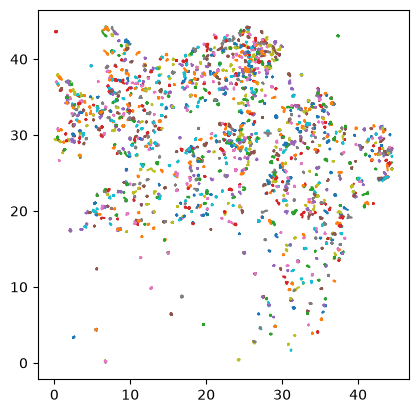

In [3]:
fig, ax = plt.subplots()
spt_data.plot_trajectories(ax=ax)

Let's use matplotlib's functionality to have a closer look:

(20.0, 30.0)

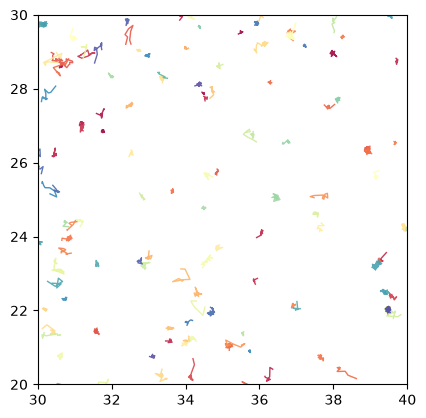

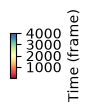

In [4]:
fig, ax = plt.subplots()
spt_data.plot_trajectories(ax=ax, color_by='time', cmap='Spectral', alpha=0.9, linewidth=1)
ax.set_xlim(30, 40)
ax.set_ylim(20, 30)

saving cbar_density


Text(0, 0.5, '')

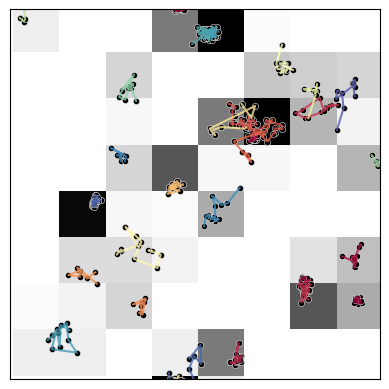

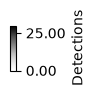

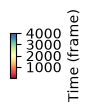

In [5]:
# maybe you like the look of plotting detections with the trajectory, you can over lay multiple plots quite easily:

fig, ax = plt.subplots()
spt_data.plot_2dhist(ax=ax, binsize=0.5, vmin=0, vmax=30, cmap='Greys') # 2D histogram of detections
spt_data.plot_scatter(ax=ax, s=20, color='black', alpha=1) # scatter plot of detections
spt_data.plot_trajectories(ax=ax, color_by='time', cmap='Spectral', alpha=0.8) # trajectories
ax.set_xlim(28, 32)
ax.set_ylim(26, 30)

# since matplotlib background, again you can make easy changes
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(None)
ax.set_ylabel(None)


Lets analyse the trajectories within this region:

# of trajectories: 1911


C:\Users\uqkkudo\Documents\python_projects\tdhelper\src\tdhelper\_msd.py:70: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  msd_sem_values[i] = sem(vector)


median Dapp: 0.00522044853686294
mean Dapp: 0.05049754223697419


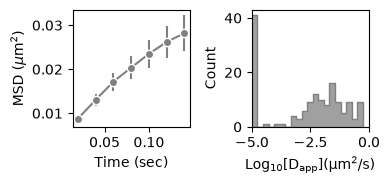

In [6]:
# filter by those trajectories whose centroid is within a small square
# before we filter, lets deep copy the data to a new TrajectoryData() object

spt_data_filtered = copy.deepcopy(spt_data)
spt_data_filtered.filter_by_centroid(xmin=30, xmax=40, ymin=20, ymax=30)

# lets see how many trajectories we have in this region:
print('# of trajectories: {}'.format(len(spt_data.data.tr.unique())))

# using spt_data functions to create MSD_dict and DCOEF_dict
MSD_dict = spt_data_filtered.calc_MSD()
DCOEF_dict = spt_data_filtered.calc_DCOEF(MSD_dict, DT)

# create a matplotlib figure that we can plot onto
fig, ax = plt.subplots(1, 2, figsize=(4,2), layout='tight')

# plotting the MSD
spt_data_filtered.plot_mean_msds(ax[0], DT=DT, color='grey', plot_x_limit=8) # you'll get a warning here because it will try to calculate SEM with only one trajectory at the longest lag-times

# plotting the diffusion coefficient distribution, lets use seaborn
sns.histplot(np.log10(list(DCOEF_dict.values())), stat='count', bins=20, color='grey', ax=ax[1], element='step')
ax[1].set_xlim(-5, 0)
ax[1].set_xlabel(r'$\mathrm{Log_{10}[D_{app}] (\mu m^2/s}$)')
ax[1].set_box_aspect(1)

print('median Dapp: {}'.format(np.median(list(DCOEF_dict.values()))))
print('mean Dapp: {}'.format(np.mean(list(DCOEF_dict.values()))))


Lets plot the trajectories again, but this time colour by diffusion coefficient:

(20.0, 30.0)

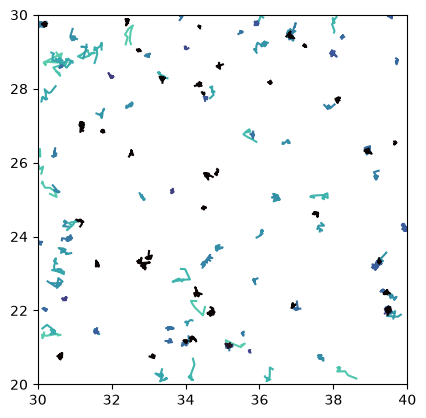

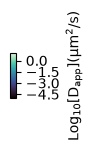

In [7]:
fig, ax = plt.subplots()
spt_data_filtered.plot_trajectories(ax=ax, color_by='dcoef', diff_dict=DCOEF_dict, palette='mako')
ax.set_xlim(30, 40)
ax.set_ylim(20, 30)


Matplotlib is fantastic for creating publication-quality figures, BUT, Plotly is great for interactive plots. So we've included functionality to be able to explore your data more interactively through plotly. 
Running this cell will open up an interactive plot in your browser.

In [8]:
spt_data_filtered.plot_3dtrajectories_px()

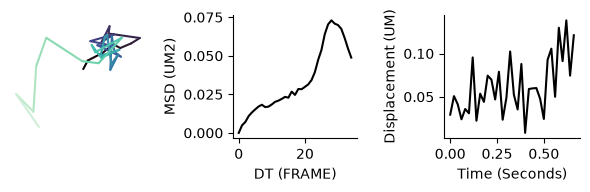

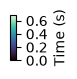

In [ ]:
# from exploring the data, trajectory ID 792 looks interesting, lets plot just that one:
tr_id = 792
fig, ax = plt.subplots(1, 3, figsize=(6,2), layout='tight')
spt_data.plot_trajectory_color_time(ax=ax[0], tr_id=tr_id, DT=DT, palette='mako')
ax[0].set_axis_off()
ax[1].plot(np.arange(0, len(MSD_dict[tr_id])), MSD_dict[tr_id], color='black')
ax[1].set_box_aspect('1')
ax[1].set_xlabel('DT (FRAME)')
ax[1].set_ylabel('MSD (UM2)')
sns.despine(ax=ax[1])

# get the trajectories displacement
spec_data = copy.deepcopy(spt_data)
spec_data.filter_by_tr(tr_id=[tr_id])
DISP_dict = spec_data.calc_DISPLACEMENTS()
ax[2].plot(np.arange(0, len(DISP_dict[tr_id]))*DT, DISP_dict[tr_id], color='black')
ax[2].set_xlabel('Time (Seconds)')
ax[2].set_ylabel('Displacement (UM)')
sns.despine(ax=ax[2])




In [10]:
# it looks like the trajectory appears trapped but then exits later, we can use a sliding window to calculate diffusion coefficients